# Topografía de los sitios objetivo y comparación por sitio (v2) · Tierra con Copernicus GLO-30
**NASA Space Apps Challenge 2026** · Igual que `topografia_sitios_v1`, con dos cambios:

1. **Tierra con Copernicus GLO-30** (histogramas de `topografia_v2`) en lugar de ASTER: menos ruido vertical, así que las llanuras de la Tierra
   pueden bajar de los 15–20 m de relieve que marcaba ASTER.
2. **Relieve en intervalos de 1 m** (antes 5 m), en la Luna, Marte y la Tierra, para separar llanuras de 5, 10 y 15 m.

| Cuerpo | Sitios (capa `sitios_v0`) | Modelo de elevación | Escala |
|---|---|---|---|
| Luna, al sur de 75° S | 9 regiones Artemis (polígono), IM-1, IM-2, Chang'e 7 | LRO LOLA `LDEM_75S_240M` | 240 m |
| Luna, resto | Apollo y aterrizajes robóticos (radio de 10 km) | LRO LOLA `LDEM_128` | ~237 m |
| Marte | 47 Exploration Zones y aterrizajes (radio de 25 km) | USGS HRSC–MOLA Blended DEM 200 m v2 | 200 m |
| Tierra | regiones candidatas y análogos conocidos | histogramas de `topografia_v2` (Copernicus promediado a ~240 m) | ~240 m |

**Comparación**: igual que v1 (KS de pendiente y de relieve; parecido si la media ≤ 0,2).

**Requisitos**: `topografia_v2` terminado. Los recortes de la Luna y Marte de v0/v1 se reutilizan: no se descarga nada de Marte.

## 0. Instalación

In [1]:
!pip install -q rasterio

## 1. Configuración y funciones comunes

In [2]:
import os, re, json, glob, datetime, unicodedata
import numpy as np, pandas as pd, requests, geopandas as gpd, rasterio
from scipy import ndimage
import matplotlib.pyplot as plt
from rasterio.windows import Window
from pyproj import CRS, Transformer
from shapely import contains_xy
from shapely.geometry import shape
from IPython.display import display
from google.colab import drive

drive.mount("/content/drive")
for raiz in ["/content/drive/MyDrive", "/content/drive/My Drive"]:
    if os.path.isdir(raiz):
        break
BASE = f"{raiz}/Hackathon Nasa"
VERSION = "topografia_sitios_v2"
RES, WEB = f"{BASE}/04_resultados/{VERSION}", f"{BASE}/06_web/{VERSION}"
CACHE_T = f"{BASE}/03_datos/cache_api/topografia"          # etiqueta de LDEM_128 (de topografia_v0)
CACHE_T1 = f"{BASE}/03_datos/cache_api/topografia_v2"      # histogramas de la Tierra (de topografia_v2, Copernicus)
CACHE = f"{BASE}/03_datos/cache_api/topografia_sitios"     # recortes de LOLA y HRSC (compartidos con v0)
BRUTOS = f"{BASE}/03_datos/brutos/topografia"
for d in (RES, WEB, CACHE, BRUTOS):
    os.makedirs(d, exist_ok=True)

R_LUNA, R_MARTE = 1737400.0, 3396190.0
RADIO_LUNA_KM, RADIO_MARTE_KM = 10, 25          # alrededor de cada punto (en Marte, el centro de la EZ, de 100 km de radio)
PRODUCTO_POLAR = "LDEM_75S_240M"
URL_MARTE = "https://planetarymaps.usgs.gov/mosaic/Mars/HRSC_MOLA_Blend/Mars_HRSC_MOLA_BlendDEM_Global_200mp_v2.tif"
PASO_BIN = 0.25; BINS = np.arange(0, 90 + PASO_BIN, PASO_BIN)
UMBRAL_PARECIDO = 0.2
LADO_RELIEVE_M = 1200                  # igual que en topografia_v1 y v2
PASO_REL = 1; BINS_REL = np.arange(0, 3000 + PASO_REL, PASO_REL)

FIGURAS = f"{RES}/figuras"; os.makedirs(FIGURAS, exist_ok=True)
_mostrar = getattr(plt, "_show_original", plt.show); plt._show_original = _mostrar
_n_fig = [0]
def _mostrar_y_guardar(*a, **k):
    fig = plt.gcf()
    if fig.axes:
        _n_fig[0] += 1
        titulo = next((ax.get_title() for ax in fig.axes if ax.get_title()), "figura")
        slug = re.sub(r"[^a-zA-Z0-9]+", "_", unicodedata.normalize("NFKD", titulo).encode("ascii", "ignore").decode()).strip("_").lower()[:50]
        fig.savefig(f"{FIGURAS}/fig_{_n_fig[0]:02d}_{slug}.png", dpi=80, bbox_inches="tight")
    _mostrar(*a, **k)
plt.show = _mostrar_y_guardar

def pendiente(z, dy, dx_filas):
    gy, gx = np.gradient(z)
    return np.degrees(np.arctan(np.hypot(gx / np.asarray(dx_filas)[:, None], gy / dy)))

def estadisticas(h, bins=BINS, umbrales=(5, 10, 15)):
    h = np.asarray(h, float); tot = h.sum()
    if tot == 0:
        return dict(mediana=np.nan, p90=np.nan, **{f"pct_lt{u}": np.nan for u in umbrales})
    acum = np.cumsum(h) / tot
    q = lambda p: float(bins[1:][np.searchsorted(acum, p)])
    paso = bins[1] - bins[0]
    return dict(mediana=q(0.5), p90=q(0.9), **{f"pct_lt{u}": float(acum[int(round(u / paso)) - 1] * 100) for u in umbrales})

def impar(n):
    n = max(int(round(n)), 3)
    return n if n % 2 else n + 1

def relieve(z, dy, dx):
    """Desnivel (máximo − mínimo) en una ventana de ~LADO_RELIEVE_M (misma función que topografia_v1)."""
    tam = (impar(LADO_RELIEVE_M / dy), impar(LADO_RELIEVE_M / dx))
    hueco = ~np.isfinite(z)
    zf = np.where(hueco, np.nanmean(z) if np.isfinite(z).any() else 0, z)
    r = ndimage.maximum_filter(zf, size=tam) - ndimage.minimum_filter(zf, size=tam)
    r[ndimage.maximum_filter(hueco.astype(np.uint8), size=tam) > 0] = np.nan
    return r

def hist_relieve(r, dentro):
    v = r[dentro & np.isfinite(r)]
    return np.histogram(np.clip(v, 0, BINS_REL[-1] - 0.01), BINS_REL)[0]

def histograma(s):
    s = s[np.isfinite(s)]
    return np.histogram(s, BINS)[0], int(s.size)

def circulo(shape_, c_fila, c_col, dy, dx_filas, radio_m):
    yy, xx = np.mgrid[:shape_[0], :shape_[1]]
    return np.hypot((yy - c_fila) * dy, (xx - c_col) * np.asarray(dx_filas)[:, None]) <= radio_m

sitios = gpd.read_file(f"{BASE}/06_web/sitios_v0/sitios.geojson")
INCLUIR_CUEVAS = True    # cuevas de la Luna y Marte como sitios (las crea cuevas_v2)
_ruta_cuevas = f"{BASE}/06_web/sitios_cuevas_v0/sitios_cuevas.geojson"
if INCLUIR_CUEVAS and os.path.exists(_ruta_cuevas):
    _c = gpd.read_file(_ruta_cuevas).to_crs(sitios.crs)
    sitios = gpd.GeoDataFrame(pd.concat([sitios, _c[[c for c in sitios.columns if c in _c.columns]]], ignore_index=True), crs=sitios.crs)
    print(f"+ {len(_c)} sitios-cueva de cuevas_v2")
polar = gpd.read_file(f"{BASE}/03_datos/procesados/sitios_luna_polar.gpkg")
print(sitios.groupby(["cuerpo", "tipo"]).size())

Mounted at /content/drive
+ 63 sitios-cueva de cuevas_v2
cuerpo  tipo                     
luna    aterrizaje_planificado        1
        aterrizaje_robotico          22
        aterrizaje_tripulado          6
        cueva_luna                   29
        region_aterrizaje_artemis     9
marte   aterrizaje_planificado        1
        aterrizaje_robotico          11
        cueva_marte                  34
        exploration_zone             47
dtype: int64


## 2. Luna, polo sur: LOLA `LDEM_75S_240M`
Se descarga entero (28 MB, se guarda en `03_datos/brutos/topografia/`). La orientación de la rejilla polar se comprueba
automáticamente comparando con `LDEM_128` en 30 puntos entre 76° S y 84° S: se elige la que da mayor correlación de alturas.

In [3]:
BASES_LOLA = {"polar": ["https://pds-geosciences.wustl.edu/lro/lro-l-lola-3-rdr-v1/lrolol_1xxx/data/lola_gdr/polar/img/",
                        "https://pds-geosciences.wustl.edu/lro/lro-l-lola-3-rdr-v1/lrolol_1xxx/DATA/LOLA_GDR/POLAR/IMG/",
                        "https://imbrium.mit.edu/DATA/LOLA_GDR/POLAR/IMG/"],
              "cyl": ["https://pds-geosciences.wustl.edu/lro/lro-l-lola-3-rdr-v1/lrolol_1xxx/data/lola_gdr/cylindrical/img/",
                      "https://pds-geosciences.wustl.edu/lro/lro-l-lola-3-rdr-v1/lrolol_1xxx/DATA/LOLA_GDR/CYLINDRICAL/IMG/",
                      "https://imbrium.mit.edu/DATA/LOLA_GDR/CYLINDRICAL/IMG/"]}

def campo(txt, k, defecto=None):
    m = re.search(rf"^\s*{k}\s*=\s*\"?([^\s\"<,)]+)", txt, re.M)
    return m.group(1) if m else defecto

def unidad(txt):
    m = re.search(r"^\s*UNIT\s*=\s*\"?([A-Za-z]+)", txt, re.M)
    return m.group(1).upper() if m else None

def etiqueta(producto, tipo, cache_dir):
    """Busca la etiqueta .LBL del producto en PDS (minúsculas o mayúsculas) o en la réplica del MIT; la guarda con la URL del .IMG."""
    ruta, ruta_url = f"{cache_dir}/{producto}.LBL", f"{cache_dir}/{producto}.url"
    if os.path.exists(ruta) and os.path.exists(ruta_url):
        return open(ruta).read(), open(ruta_url).read().strip()
    for b in BASES_LOLA[tipo]:
        for lbl, img in ((producto.lower() + ".lbl", producto.lower() + ".img"), (producto + ".LBL", producto + ".IMG")):
            try:
                r = requests.get(b + lbl, timeout=60)
            except requests.RequestException:
                continue
            if r.status_code == 200 and "LINE_SAMPLES" in r.text:
                open(ruta, "w").write(r.text); open(ruta_url, "w").write(b + img)
                return r.text, b + img
    raise RuntimeError(f"No encuentro {producto}.LBL en PDS ni en imbrium.mit.edu")

def tipo_dato(txt):
    st, bits = campo(txt, "SAMPLE_TYPE", ""), int(campo(txt, "SAMPLE_BITS", "16"))
    orden = "<" if ("LSB" in st or "PC" in st) else ">"
    return np.dtype(f"{orden}f{bits // 8}" if "REAL" in st else f"{orden}i{bits // 8}")

# --- Producto polar ---
LBL_P, URL_P = etiqueta(PRODUCTO_POLAR, "polar", BRUTOS)
RUTA_P = f"{BRUTOS}/{PRODUCTO_POLAR}.IMG"
L_P, S_P = int(campo(LBL_P, "LINES")), int(campo(LBL_P, "LINE_SAMPLES"))
DT_P = tipo_dato(LBL_P)
if not (os.path.exists(RUTA_P) and os.path.getsize(RUTA_P) == L_P * S_P * DT_P.itemsize):
    with requests.get(URL_P, stream=True, timeout=600) as r:
        r.raise_for_status()
        with open(RUTA_P, "wb") as f:
            for t in r.iter_content(1 << 22):
                f.write(t)
assert os.path.getsize(RUTA_P) == L_P * S_P * DT_P.itemsize, "Tamaño del IMG polar distinto del de la etiqueta"
ESCALA_P = float(campo(LBL_P, "MAP_SCALE"))                      # m/píxel
if ESCALA_P < 10: ESCALA_P *= 1000                              # por si viene en km/píxel
L0, S0 = float(campo(LBL_P, "LINE_PROJECTION_OFFSET")), float(campo(LBL_P, "SAMPLE_PROJECTION_OFFSET"))
FACTOR = float(campo(LBL_P, "SCALING_FACTOR", "1"))           # el OFFSET no cambia la pendiente
Z_P = np.memmap(RUTA_P, dtype=DT_P, mode="r", shape=(L_P, S_P))
muestra = np.asarray(Z_P[::max(1, L_P // 50), ::max(1, S_P // 50)], dtype="float64") * FACTOR
EN_KM = unidad(LBL_P) == "KILOMETER" or np.nanmax(np.abs(muestra)) < 30          # alturas en km → se pasan a m
A_METROS = 1000.0 if EN_KM else 1.0
print(f"{PRODUCTO_POLAR}: {L_P}×{S_P} px de {ESCALA_P:.0f} m · {DT_P} · unidad {'km' if EN_KM else 'm'} · {URL_P}")

CRS_SP = CRS.from_proj4(f"+proj=stere +lat_0=-90 +lon_0=0 +k=1 +x_0=0 +y_0=0 +R={R_LUNA} +units=m +no_defs")
GEO_LUNA = CRS.from_proj4(f"+proj=longlat +R={R_LUNA} +no_defs")
a_polar = Transformer.from_crs(GEO_LUNA, CRS_SP, always_xy=True)

def xy_a_pixel(x, y, o):
    sx, sy, cambio = o
    if cambio: x, y = y, x
    return L0 - (sy * y) / ESCALA_P, S0 + (sx * x) / ESCALA_P          # fila, columna (base 0, centro de píxel)

def pixel_a_xy(fila, col, o):
    sx, sy, cambio = o
    x, y = (col - S0) * ESCALA_P / sx, (L0 - fila) * ESCALA_P / sy
    return (y, x) if cambio else (x, y)

def altura_polar(filas, cols):
    f, c = np.round(filas).astype(int), np.round(cols).astype(int)
    ok = (f >= 0) & (f < L_P) & (c >= 0) & (c < S_P)
    out = np.full(f.shape, np.nan)
    out[ok] = np.asarray(Z_P[f[ok], c[ok]], dtype="float64") * FACTOR * A_METROS
    return out

LDEM_75S_240M: 3812×3812 px de 240 m · int16 · unidad m · https://pds-geosciences.wustl.edu/lro/lro-l-lola-3-rdr-v1/lrolol_1xxx/data/lola_gdr/polar/img/ldem_75s_240m.img


In [4]:
# --- LDEM_128 (cilíndrico): lectura por filas, como en topografia_v0 ---
LBL_C, URL_C = etiqueta("LDEM_128", "cyl", CACHE_T)
L_C, S_C, PPD = int(campo(LBL_C, "LINES")), int(campo(LBL_C, "LINE_SAMPLES")), float(campo(LBL_C, "MAP_RESOLUTION"))
DT_C = tipo_dato(LBL_C); FACTOR_C = float(campo(LBL_C, "SCALING_FACTOR", "0.5"))
LATMAX_C, LONW_C = float(campo(LBL_C, "MAXIMUM_LATITUDE", "90")), float(campo(LBL_C, "WESTERNMOST_LONGITUDE", "0"))

def filas_cyl(f0, f1):
    r = requests.get(URL_C, headers={"Range": f"bytes={f0 * S_C * DT_C.itemsize}-{f1 * S_C * DT_C.itemsize - 1}"}, timeout=300)
    assert r.status_code == 206, f"El servidor no acepta peticiones parciales (HTTP {r.status_code})"
    return np.frombuffer(r.content, dtype=DT_C).reshape(f1 - f0, S_C).astype("float32") * FACTOR_C

def recorte_cyl(ident, lat, lon, radio_km):
    ruta = f"{CACHE}/lola128_{ident}.npz"
    if os.path.exists(ruta):
        return dict(np.load(ruta))
    px = 2 * np.pi * R_LUNA / 360 / PPD
    medio = int(np.ceil(radio_km * 1000 / px)) + 2
    medio_c = int(np.ceil(medio / max(np.cos(np.radians(lat)), 0.05)))
    fila = int(np.floor((LATMAX_C - lat) * PPD)); col = int(np.floor(((lon - LONW_C) % 360) * PPD))
    bloque = filas_cyl(fila - medio, fila + medio + 1)
    h = bloque[:, np.arange(col - medio_c, col + medio_c + 1) % S_C]
    out = {"h": h, "lat_f": LATMAX_C - (np.arange(fila - medio, fila + medio + 1) + 0.5) / PPD}
    np.savez(ruta, **out)
    return out

# --- Orientación de la rejilla polar: 30 puntos entre 76° S y 84° S comparados con LDEM_128 ---
lats_c = np.repeat([-76.0, -78.0, -80.0, -82.0, -84.0], 6); lons_c = np.tile(np.arange(-150, 180, 60.0), 5)
filas_ref = {la: filas_cyl(int(np.floor((LATMAX_C - la) * PPD)), int(np.floor((LATMAX_C - la) * PPD)) + 1)[0] for la in np.unique(lats_c)}
ref = np.array([filas_ref[la][int(np.floor(((lo - LONW_C) % 360) * PPD)) % S_C] for la, lo in zip(lats_c, lons_c)])
X, Y = a_polar.transform(lons_c, lats_c)
pruebas = {}
for o in [(sx, sy, cb) for cb in (False, True) for sx in (1, -1) for sy in (1, -1)]:
    f, c = xy_a_pixel(np.asarray(X), np.asarray(Y), o)
    h = altura_polar(f, c)
    ok = np.isfinite(h)
    pruebas[o] = np.corrcoef(h[ok], ref[ok])[0, 1] if ok.sum() > 10 else -1
ORIENT = max(pruebas, key=pruebas.get)
print("Correlación con LDEM_128 por orientación:", {str(k): round(v, 3) for k, v in pruebas.items()})
assert pruebas[ORIENT] > 0.9, "Ninguna orientación coincide con LDEM_128: revisa la etiqueta del producto polar"
print("Orientación elegida:", ORIENT, f"(r = {pruebas[ORIENT]:.3f})")

Correlación con LDEM_128 por orientación: {'(1, 1, False)': np.float64(1.0), '(1, -1, False)': np.float64(-0.052), '(-1, 1, False)': np.float64(0.094), '(-1, -1, False)': np.float64(-0.615), '(1, 1, True)': np.float64(0.435), '(1, -1, True)': np.float64(-0.302), '(-1, 1, True)': np.float64(0.229), '(-1, -1, True)': np.float64(-0.359)}
Orientación elegida: (1, 1, False) (r = 1.000)


In [5]:
def ventana_polar(geom_xy, margen=3):
    """Recorta el producto polar alrededor de una geometría en metros (estereográfica polar sur) y devuelve alturas y máscara."""
    x0, y0, x1, y1 = geom_xy.bounds
    esquinas = [xy_a_pixel(np.array([x]), np.array([y]), ORIENT) for x in (x0, x1) for y in (y0, y1)]
    fs = [e[0][0] for e in esquinas]; cs = [e[1][0] for e in esquinas]
    f0, f1 = max(int(np.floor(min(fs))) - margen, 0), min(int(np.ceil(max(fs))) + margen + 1, L_P)
    c0, c1 = max(int(np.floor(min(cs))) - margen, 0), min(int(np.ceil(max(cs))) + margen + 1, S_P)
    z = np.asarray(Z_P[f0:f1, c0:c1], dtype="float64") * FACTOR * A_METROS
    ff, cc = np.mgrid[f0:f1, c0:c1]
    xx, yy = pixel_a_xy(ff.astype(float), cc.astype(float), ORIENT)
    return z, contains_xy(geom_xy, xx, yy)

filas_s, HIST, HREL = [], {}, {}
def registrar(ident, nombre, cuerpo, tipo, h, n, dem, hr):
    HIST[ident], HREL[ident] = h, hr
    filas_s.append({"id": ident, "nombre": nombre, "cuerpo": cuerpo, "tipo": tipo, "dem": dem, "n_px": n,
                    **{k: round(v, 1) for k, v in estadisticas(h).items()},
                    **{f"relieve_{k}": round(v, 1) for k, v in estadisticas(hr, BINS_REL, (50, 100, 200)).items()}})

# Regiones Artemis (polígonos)
por_nombre = {r.region: r.geometry for r in polar.itertuples()}
for r in sitios[sitios.tipo == "region_aterrizaje_artemis"].itertuples():
    geom = por_nombre[r.nombre]
    z, dentro = ventana_polar(geom)
    s = pendiente(z, ESCALA_P, np.full(z.shape[0], ESCALA_P))
    h, n = histograma(np.where(dentro, s, np.nan))
    registrar(r.id, r.nombre, "luna", r.tipo, h, n, PRODUCTO_POLAR, hist_relieve(relieve(z, ESCALA_P, ESCALA_P), dentro))

# Puntos al sur de 75° S (IM-1, IM-2, Chang'e 7…): círculo de 10 km
for r in sitios[(sitios.cuerpo == "luna") & (sitios.geometry.geom_type == "Point")].itertuples():
    if r.geometry.y >= -75:
        continue
    x, y = a_polar.transform(r.geometry.x, r.geometry.y)
    z, dentro = ventana_polar(gpd.GeoSeries.from_xy([x], [y])[0].buffer(RADIO_LUNA_KM * 1000))
    s = pendiente(z, ESCALA_P, np.full(z.shape[0], ESCALA_P))
    h, n = histograma(np.where(dentro, s, np.nan))
    registrar(r.id, r.nombre, "luna", r.tipo, h, n, PRODUCTO_POLAR, hist_relieve(relieve(z, ESCALA_P, ESCALA_P), dentro))
print(f"Sitios del polo sur: {len(filas_s)}")
pd.DataFrame(filas_s)[["nombre", "tipo", "n_px", "mediana", "p90", "pct_lt10", "relieve_mediana", "relieve_p90"]]

Sitios del polo sur: 12


,nombre,tipo,n_px,mediana,p90,pct_lt10,relieve_mediana,relieve_p90
0,Peak Near Cabeus B,region_aterrizaje_artemis,6972,19.0,25.5,8.1,407.0,608.0
1,Haworth,region_aterrizaje_artemis,15376,9.8,17.5,53.2,198.0,363.0
2,Malapert Massif,region_aterrizaje_artemis,7690,17.5,25.8,18.1,371.0,537.0
3,Mons Mouton Plateau,region_aterrizaje_artemis,77361,10.5,22.0,48.0,216.0,470.0
4,Mons Mouton,region_aterrizaje_artemis,4489,10.8,22.0,45.8,219.0,509.0
5,Nobile Rim 1,region_aterrizaje_artemis,6972,17.8,26.0,21.3,381.0,648.0
6,Nobile Rim 2,region_aterrizaje_artemis,7056,10.8,21.5,46.6,226.0,479.0
7,de Gerlache Rim 2,region_aterrizaje_artemis,6978,12.2,19.8,34.5,264.0,425.0
8,Slater Plain,region_aterrizaje_artemis,6889,8.0,16.5,65.4,164.0,343.0
9,IM-1 Odysseus,aterrizaje_robotico,5452,11.5,23.0,43.7,229.0,500.0


## 3. Luna, resto de sitios: LOLA `LDEM_128` (radio de 10 km)

In [6]:
px_c = 2 * np.pi * R_LUNA / 360 / PPD
n0 = len(filas_s)
for r in sitios[(sitios.cuerpo == "luna") & (sitios.geometry.geom_type == "Point")].itertuples():
    if r.geometry.y < -75:
        continue
    d = recorte_cyl(r.id, r.geometry.y, r.geometry.x, RADIO_LUNA_KM)
    dx = px_c * np.cos(np.radians(d["lat_f"]))
    s = pendiente(d["h"], px_c, dx)
    dentro = circulo(s.shape, s.shape[0] // 2, s.shape[1] // 2, px_c, dx, RADIO_LUNA_KM * 1000)
    h, n = histograma(np.where(dentro, s, np.nan))
    registrar(r.id, r.nombre, "luna", r.tipo, h, n, "LDEM_128", hist_relieve(relieve(d["h"], px_c, float(np.mean(dx))), dentro))
print(f"Sitios lunares con LDEM_128: {len(filas_s) - n0}")

Sitios lunares con LDEM_128: 55


## 4. Marte: HRSC–MOLA Blended DEM 200 m (USGS)
El archivo global pesa 11 GB: se leen solo ventanas de ±25 km alrededor de cada sitio directamente desde el servidor del USGS
(cada recorte se guarda en `03_datos/cache_api/topografia_sitios/`). El GeoTIFF está en grados (ESRI:104971) y guardado por filas,
así que cada sitio descarga unos 50 MB de filas completas. Si ya ejecutaste `topografia_sitios_v0`, los recortes ya están y no se descarga nada.

In [7]:
os.environ.setdefault("GDAL_DISABLE_READDIR_ON_OPEN", "EMPTY_DIR")
os.environ.setdefault("CPL_VSIL_CURL_ALLOWED_EXTENSIONS", ".tif")
# El GeoTIFF está guardado fila a fila: se piden trozos grandes y se unen las filas consecutivas en una sola petición
os.environ.setdefault("GDAL_HTTP_MERGE_CONSECUTIVE_RANGES", "YES")
os.environ.setdefault("CPL_VSIL_CURL_CHUNK_SIZE", str(8 * 1024 * 1024))
os.environ.setdefault("GDAL_HTTP_MAX_RETRY", "5"); os.environ.setdefault("GDAL_HTTP_RETRY_DELAY", "2")
puntos_m = sitios[sitios.cuerpo == "marte"]
pendientes_m = [r for r in puntos_m.itertuples() if not os.path.exists(f"{CACHE}/hrsc_{r.id}.npz")]
fuente_m = URL_MARTE if URL_MARTE.startswith("/") else f"/vsicurl/{URL_MARTE}"
if pendientes_m:
    with rasterio.open(fuente_m) as ds:
        geografico = ds.crs.is_geographic
        print("Bloques del GeoTIFF:", ds.block_shapes[0], "| CRS:", ds.crs.to_string()[:60], "| píxel:", ds.res,
              "| en grados" if geografico else "| en metros")
        crs_pp = CRS.from_user_input(ds.crs.to_wkt())                  # CRS de pyproj (tiene elipsoide y CRS geográfico)
        R_DS = (crs_pp.ellipsoid.semi_major_metre if crs_pp.ellipsoid else None) or R_MARTE
        if geografico:
            dy_m = abs(ds.res[1]) * np.pi * R_DS / 180                 # el píxel viene en grados: se pasa a metros
        else:
            dy_m = abs(ds.res[1])
            a_m = Transformer.from_crs(crs_pp.geodetic_crs or CRS.from_proj4(f"+proj=longlat +R={R_MARTE} +no_defs"), crs_pp, always_xy=True)
        print(f"Píxel ≈ {dy_m:.0f} m · ventana de ±{RADIO_MARTE_KM} km")
        for k, r in enumerate(pendientes_m):
            lon, lat = ((r.geometry.x + 180) % 360) - 180, r.geometry.y
            x, y = (lon, lat) if geografico else a_m.transform(lon, lat)
            fila, col = ds.index(x, y)
            medio = int(np.ceil(RADIO_MARTE_KM * 1000 / dy_m)) + 2
            medio_c = int(np.ceil(medio / max(np.cos(np.radians(lat)), 0.2)))
            assert medio < 5000 and medio_c < 20000, f"Ventana demasiado grande ({medio}×{medio_c} px): revisa las unidades del píxel"
            win = Window(col - medio_c, fila - medio, 2 * medio_c + 1, 2 * medio + 1)
            nd = ds.nodata if ds.nodata is not None else -32768
            z = ds.read(1, window=win, boundless=True, fill_value=nd).astype("float32")
            z[z == nd] = np.nan
            z = z * (ds.scales[0] or 1) + (ds.offsets[0] or 0)
            lat_f = lat - (np.arange(z.shape[0]) - medio) * dy_m / (np.pi * R_DS / 180)
            dx0 = dy_m if geografico else abs(ds.res[0])
            np.savez(f"{CACHE}/hrsc_{r.id}.npz", h=z, lat_f=lat_f, dy=dy_m, dx0=dx0)
            if k % 10 == 0:
                print(f"  {k + 1}/{len(pendientes_m)} {r.nombre}")
n0 = len(filas_s)
for r in puntos_m.itertuples():
    d = dict(np.load(f"{CACHE}/hrsc_{r.id}.npz"))
    dx = float(d["dx0"]) * np.cos(np.radians(d["lat_f"]))
    s = pendiente(d["h"], float(d["dy"]), dx)
    dentro = circulo(s.shape, s.shape[0] // 2, s.shape[1] // 2, float(d["dy"]), dx, RADIO_MARTE_KM * 1000)
    h, n = histograma(np.where(dentro, s, np.nan))
    hr = hist_relieve(relieve(d["h"], float(d["dy"]), float(np.mean(dx))), dentro)
    registrar(r.id, r.nombre, "marte", r.tipo, h, n, "HRSC-MOLA 200 m", hr)
print(f"Sitios de Marte: {len(filas_s) - n0}")

Bloques del GeoTIFF: (1, 106694) | CRS: ESRI:104971 | píxel: (0.003374120830641, 0.003374120830641) | en grados
Píxel ≈ 200 m · ventana de ±25 km
  1/34 CC0093
  11/34 CC0803
  21/34 APC099
  31/34 CC0274
Sitios de Marte: 93


## 5. Tierra: histogramas de pendiente y relieve a ~240 m (de `topografia_v2`)
Regiones candidatas completas y análogos conocidos, con Copernicus GLO-30.

In [8]:
ruta_t1 = f"{BASE}/06_web/topografia_v2/topografia.json"
assert os.path.exists(ruta_t1), "Falta topografia_v2: ejecútalo (hasta que ponga ✅) antes que este notebook"
topo_t = json.load(open(ruta_t1, encoding="utf-8"))["regiones"]
incompletas = [rid for rid, v in topo_t.items() if not v.get("completa")]
if incompletas:
    print(f"⚠ {len(incompletas)} regiones de topografia_v2 sin terminar: {incompletas[:5]}… Vuelve a ejecutar topografia_v2 para completarlas.")
H_T, HR_T = {}, {}
for ruta in glob.glob(f"{CACHE_T1}/*__*.npz"):
    rid = os.path.basename(ruta).split("__")[0]
    d = np.load(ruta)
    if "h240" not in d.files:
        continue
    assert len(d["h240"]) == len(BINS) - 1 and len(d["hrel"]) == len(BINS_REL) - 1, "Intervalos distintos de topografia_v2 (¿PASO_REL = 1 en los dos?)"
    H_T[rid] = H_T.get(rid, 0) + d["h240"].astype(float); HR_T[rid] = HR_T.get(rid, 0) + d["hrel"].astype(float)
tierra = pd.DataFrame([{"region_id": rid, "cuerpo": topo_t.get(rid, {}).get("cuerpo"), "tipo_t": topo_t.get(rid, {}).get("tipo"),
                        "region": topo_t.get(rid, {}).get("region"), "n_px_240m": int(h.sum()),
                        **{k: round(v, 1) for k, v in estadisticas(h).items()},
                        **{f"relieve_{k}": round(v, 1) for k, v in estadisticas(HR_T[rid], BINS_REL, (50, 100, 200)).items()}}
                       for rid, h in H_T.items() if h.sum() > 0 and rid in topo_t])
print(tierra.groupby(["cuerpo", "tipo_t"]).size())

cuerpo  tipo_t          
luna    analogo_conocido     7
        region_candidata    20
marte   analogo_conocido     8
        region_candidata    21
dtype: int64


## 6. Comparación por sitio (pendiente + relieve)
Para cada sitio: distancia KS de pendiente, distancia KS de relieve y su media (**combinada**). Se compara con todas las regiones
candidatas y análogos conocidos de la Tierra del mismo perfil (Luna con Luna, Marte con Marte).

In [9]:
cdf = lambda h: np.cumsum(h) / h.sum()
ks = lambda a, b: float(np.max(np.abs(cdf(a) - cdf(b))))
sit = pd.DataFrame(filas_s)
# Se compara cada sitio con TODAS las regiones de la Tierra (de los dos perfiles): la capa de geología (geologia_v0) usa
# la tabla completa. La tabla de siempre (similitud_sitio_tierra.csv, la que lee clima_v1) sigue siendo solo del mismo perfil.
todas = []
for r in sit.itertuples():
    if HIST[r.id].sum() == 0 or HREL[r.id].sum() == 0:
        continue
    for t in tierra.itertuples():
        d_p, d_r = ks(HIST[r.id], H_T[t.region_id]), ks(HREL[r.id], HR_T[t.region_id])
        todas.append({"sitio_id": r.id, "sitio": r.nombre, "tipo_sitio": r.tipo, "cuerpo": r.cuerpo,
                      "region_id": t.region_id, "region": t.region, "tipo_tierra": t.tipo_t, "perfil_tierra": t.cuerpo,
                      "ks_pendiente": round(d_p, 3), "ks_relieve": round(d_r, 3), "distancia": round((d_p + d_r) / 2, 3)})
todas = pd.DataFrame(todas).sort_values(["sitio_id", "distancia"])
todas.to_csv(f"{RES}/similitud_sitio_tierra_todas.csv", index=False)
np.savez_compressed(f"{RES}/histogramas_sitios_v2.npz", ids=np.array(list(HIST)),
                    h240=np.array([HIST[k] for k in HIST]), hrel=np.array([HREL[k] for k in HIST]))
pares = todas[todas.perfil_tierra == todas.cuerpo].drop(columns="perfil_tierra")
pares.to_csv(f"{RES}/similitud_sitio_tierra.csv", index=False)
print(f"Pares guardados: {len(todas)} con los dos perfiles · {len(pares)} del mismo perfil")
top = pares.groupby("sitio_id").head(5)

def mejor_de(df, sufijo):
    m = df.groupby("sitio_id").first()[["region_id", "region", "ks_pendiente", "ks_relieve", "distancia"]]
    return m.add_suffix(sufijo)
sit = (sit.merge(mejor_de(pares, "_mejor"), left_on="id", right_index=True, how="left")
          .merge(mejor_de(pares[pares.tipo_tierra == "region_candidata"], "_cand"), left_on="id", right_index=True, how="left")
          .merge(mejor_de(pares[pares.tipo_tierra == "analogo_conocido"], "_anal"), left_on="id", right_index=True, how="left"))
sit["hay_parecido"] = np.where(sit.distancia_mejor <= UMBRAL_PARECIDO, "Sí", "No")
sit.to_csv(f"{RES}/topografia_sitios_v2.csv", index=False)

cols = ["nombre", "tipo", "mediana", "relieve_mediana", "region_cand", "distancia_cand", "region_anal", "distancia_anal", "hay_parecido"]
print("Luna"); display(sit[sit.cuerpo == "luna"].sort_values("distancia_mejor")[cols])
print("Marte"); display(sit[sit.cuerpo == "marte"].sort_values("distancia_mejor")[cols])
print("Sitios con algún parecido (combinada ≤ 0,2):")
display(sit.groupby(["cuerpo", "tipo"]).hay_parecido.apply(lambda v: f"{(v == 'Sí').sum()}/{len(v)}"))

Pares guardados: 8960 con los dos perfiles · 4506 del mismo perfil
Luna


,nombre,tipo,mediana,relieve_mediana,region_cand,distancia_cand,region_anal,distancia_anal,hay_parecido
35,Chandrayaan-3,aterrizaje_robotico,3.0,63.0,"Provincia de Tabuk, Arabia Saudita",0.039,Lanzarote – Timanfaya,0.093,Sí
59,Copernicus LB3,cueva_luna,1.2,27.0,"Provincia de Medina, Arabia Saudita",0.043,"Craters of the Moon, Idaho",0.171,Sí
41,Southwest Mare Tranquillitatis Pit,cueva_luna,1.2,24.0,"Provincia de Medina, Arabia Saudita",0.067,"Craters of the Moon, Idaho",0.102,Sí
42,Southwest Mare Tranquillitatis B Pit,cueva_luna,1.2,24.0,"Provincia de Medina, Arabia Saudita",0.067,"Craters of the Moon, Idaho",0.102,Sí
64,Tycho 5b,cueva_luna,5.5,115.0,"Tibesti, Chad",0.067,"Askja, Islandia",0.143,Sí
...,...,...,...,...,...,...,...,...,...
26,Luna 17,aterrizaje_robotico,0.5,8.0,"Afar, Etiopía",0.381,"Craters of the Moon, Idaho",0.550,No
33,Chang'e 5,aterrizaje_robotico,0.5,9.0,"Afar, Etiopía",0.383,"Craters of the Moon, Idaho",0.511,No
5,Nobile Rim 1,region_aterrizaje_artemis,17.8,381.0,Irán,0.492,"Mauna Kea, Hawái",0.386,No
0,Peak Near Cabeus B,region_aterrizaje_artemis,19.0,407.0,Irán,0.646,"Mauna Kea, Hawái",0.481,No


Marte


,nombre,tipo,mediana,relieve_mediana,region_cand,distancia_cand,region_anal,distancia_anal,hay_parecido
115,Hale Crater,exploration_zone,2.8,62.0,"Región de Antofagasta, Chile",0.053,Lanzarote (ESA PANGAEA),0.118,Sí
106,Columbus Crater,exploration_zone,1.8,38.0,Groenlandia,0.056,Isla Devon (Haughton-Mars Project),0.266,Sí
109,Deuteronilus Mensae,exploration_zone,2.8,64.0,"Región de Antofagasta, Chile",0.057,Lanzarote (ESA PANGAEA),0.122,Sí
112,Deuteronilus Mensae 2,exploration_zone,1.5,35.0,Groenlandia,0.057,Cuenca de Qaidam occidental (Lenghu),0.301,Sí
81,Viking,exploration_zone,0.2,6.0,"Gobernación de Mutana, Irak",0.059,Cuenca de Qaidam occidental (Lenghu),0.440,Sí
...,...,...,...,...,...,...,...,...,...
156,CC0274,cueva_marte,0.5,12.0,"Provincia Oriental, Arabia Saudita",0.211,Cuenca de Qaidam occidental (Lenghu),0.458,No
154,CC0256,cueva_marte,0.8,16.0,"Provincia Oriental, Arabia Saudita",0.222,Cuenca de Qaidam occidental (Lenghu),0.315,No
147,APC085,cueva_marte,0.2,4.0,"Dajla-Río de Oro, Marruecos",0.232,Cuenca de Qaidam occidental (Lenghu),0.600,No
149,APC075,cueva_marte,1.5,35.0,Groenlandia,0.278,Cuenca de Qaidam occidental (Lenghu),0.469,No


Sitios con algún parecido (combinada ≤ 0,2):


cuerpo  tipo                     
luna    aterrizaje_planificado         1/1
        aterrizaje_robotico          14/22
        aterrizaje_tripulado           5/6
        cueva_luna                   20/29
        region_aterrizaje_artemis      5/9
marte   aterrizaje_planificado         1/1
        aterrizaje_robotico          11/11
        cueva_marte                  27/34
        exploration_zone             47/47
Name: hay_parecido, dtype: object

### 6.1 Cambios respecto a v1 (Tierra con ASTER, relieve cada 5 m)
¿Qué sitios ganan pareja al medir la Tierra con Copernicus?

In [10]:
v1 = f"{BASE}/04_resultados/topografia_sitios_v1/topografia_sitios_v1.csv"
if os.path.exists(v1):
    a = pd.read_csv(v1)[["id", "region_mejor", "distancia_mejor", "hay_parecido"]].rename(
        columns={"region_mejor": "region_v1", "distancia_mejor": "distancia_v1", "hay_parecido": "parecido_v1"})
    comp = sit[["id", "nombre", "cuerpo", "tipo", "relieve_mediana", "region_mejor", "distancia_mejor", "hay_parecido"]].merge(a, on="id")
    print("Sitios con parecido: v1", {c: f"{(g.parecido_v1 == 'Sí').sum()}/{len(g)}" for c, g in comp.groupby("cuerpo")},
          "→ v2", {c: f"{(g.hay_parecido == 'Sí').sum()}/{len(g)}" for c, g in comp.groupby("cuerpo")})
    ganan = comp[(comp.parecido_v1 == "No") & (comp.hay_parecido == "Sí")]
    pierden = comp[(comp.parecido_v1 == "Sí") & (comp.hay_parecido == "No")]
    print(f"Ganan pareja: {len(ganan)} · la pierden: {len(pierden)}")
    display(ganan.sort_values("distancia_mejor")); display(pierden.sort_values("distancia_mejor"))

Sitios con parecido: v1 {'luna': '26/38', 'marte': '52/59'} → v2 {'luna': '25/38', 'marte': '59/59'}
Ganan pareja: 7 · la pierden: 1


,id,nombre,cuerpo,tipo,relieve_mediana,region_mejor,distancia_mejor,hay_parecido,region_v1,distancia_v1,parecido_v1
52,ez-viking,Viking,marte,exploration_zone,6.0,"Gobernación de Mutana, Irak",0.059,Sí,"Dajla-Río de Oro, Marruecos",0.441,No
65,ez-zephyria-planum,Zephyria Planum,marte,exploration_zone,10.0,"Gobernación de Shabwah, Yemen",0.075,Sí,"Dajla-Río de Oro, Marruecos",0.211,No
88,ez-arcadia-planitia,Arcadia Planitia,marte,exploration_zone,5.0,"Gobernación de Mutana, Irak",0.104,Sí,"Dajla-Río de Oro, Marruecos",0.558,No
89,ez-erebus-montes,Erebus Montes,marte,exploration_zone,7.0,"Gobernación de Mutana, Irak",0.114,Sí,"Dajla-Río de Oro, Marruecos",0.478,No
39,aterrizaje-viking-1,Viking 1,marte,aterrizaje_robotico,8.0,"Al Wahat, Libia",0.121,Sí,"Dajla-Río de Oro, Marruecos",0.366,No
46,aterrizaje-insight,InSight,marte,aterrizaje_robotico,7.0,"Gobernación de Mutana, Irak",0.166,Sí,"Dajla-Río de Oro, Marruecos",0.458,No
93,ez-arcadia-planitia-43,Arcadia Planitia,marte,exploration_zone,8.0,"Al Wahat, Libia",0.173,Sí,"Dajla-Río de Oro, Marruecos",0.415,No


,id,nombre,cuerpo,tipo,relieve_mediana,region_mejor,distancia_mejor,hay_parecido,region_v1,distancia_v1,parecido_v1
3,artemis-mons-mouton-plateau,Mons Mouton Plateau,luna,region_aterrizaje_artemis,216.0,Irán,0.208,No,Irán,0.2,Sí


### 6.2 Análogos conocidos: ¿a qué sitios se parecen?
Validación del método: si los análogos que ya usan la NASA y la ESA se parecen a sitios reales, la medida tiene sentido.
También responde si alguno sirve para las regiones Artemis del polo sur.

In [11]:
an = pares[pares.tipo_tierra == "analogo_conocido"]
resumen_an = (an.sort_values("distancia").groupby("region_id")
                .agg(analogo=("region", "first"), cuerpo=("cuerpo", "first"), sitio_mas_parecido=("sitio", "first"),
                     distancia=("distancia", "first"), sitios_parecidos=("distancia", lambda v: int((v <= UMBRAL_PARECIDO).sum())))
                .sort_values(["cuerpo", "distancia"]))
resumen_an.to_csv(f"{RES}/analogos_conocidos_vs_sitios.csv")
display(resumen_an)
art = an[an.tipo_sitio == "region_aterrizaje_artemis"].sort_values("distancia").groupby("sitio").head(1)
print("Regiones Artemis: análogo conocido más parecido"); display(art[["sitio", "region", "ks_pendiente", "ks_relieve", "distancia"]])

,analogo,cuerpo,sitio_mas_parecido,distancia,sitios_parecidos
region_id,,,,,
analogo-luna-askja-islandia,"Askja, Islandia",luna,Apollo 16,0.076,10
analogo-luna-lanzarote-timanfaya,Lanzarote – Timanfaya,luna,Chandrayaan-3,0.093,5
analogo-luna-meteor-crater-arizona,"Meteor Crater, Arizona",luna,Luna 16,0.094,5
analogo-luna-mauna-kea-hawai,"Mauna Kea, Hawái",luna,de Gerlache Rim 2,0.097,5
analogo-luna-kilauea-hawai,"Kīlauea, Hawái",luna,Apollo 14,0.101,3
analogo-luna-craters-of-the-moon-idaho,"Craters of the Moon, Idaho",luna,Southwest Mare Tranquillitatis Pit,0.102,14
analogo-luna-pinacate-sonora,"Pinacate, Sonora",luna,Highland 3,0.107,7
analogo-marte-desierto-de-atacama-nucleo-hiperarido-ar,"Desierto de Atacama, núcleo hiperárido (ARADS)",marte,Jezero-Isidis-Syrtis,0.060,16
analogo-marte-lanzarote-esa-pangaea,Lanzarote (ESA PANGAEA),marte,Apollinaris Sulci,0.072,27


Regiones Artemis: análogo conocido más parecido


,sitio,region,ks_pendiente,ks_relieve,distancia
410,de Gerlache Rim 2,"Mauna Kea, Hawái",0.081,0.113,0.097
242,Mons Mouton,"Mauna Kea, Hawái",0.164,0.197,0.181
354,Nobile Rim 2,"Mauna Kea, Hawái",0.178,0.220,0.199
186,Mons Mouton Plateau,"Mauna Kea, Hawái",0.187,0.239,0.213
74,Haworth,"Mauna Kea, Hawái",0.226,0.262,0.244
464,Slater Plain,"Askja, Islandia",0.340,0.321,0.330
130,Malapert Massif,"Mauna Kea, Hawái",0.375,0.366,0.370
298,Nobile Rim 1,"Mauna Kea, Hawái",0.383,0.389,0.386
18,Peak Near Cabeus B,"Mauna Kea, Hawái",0.487,0.475,0.481


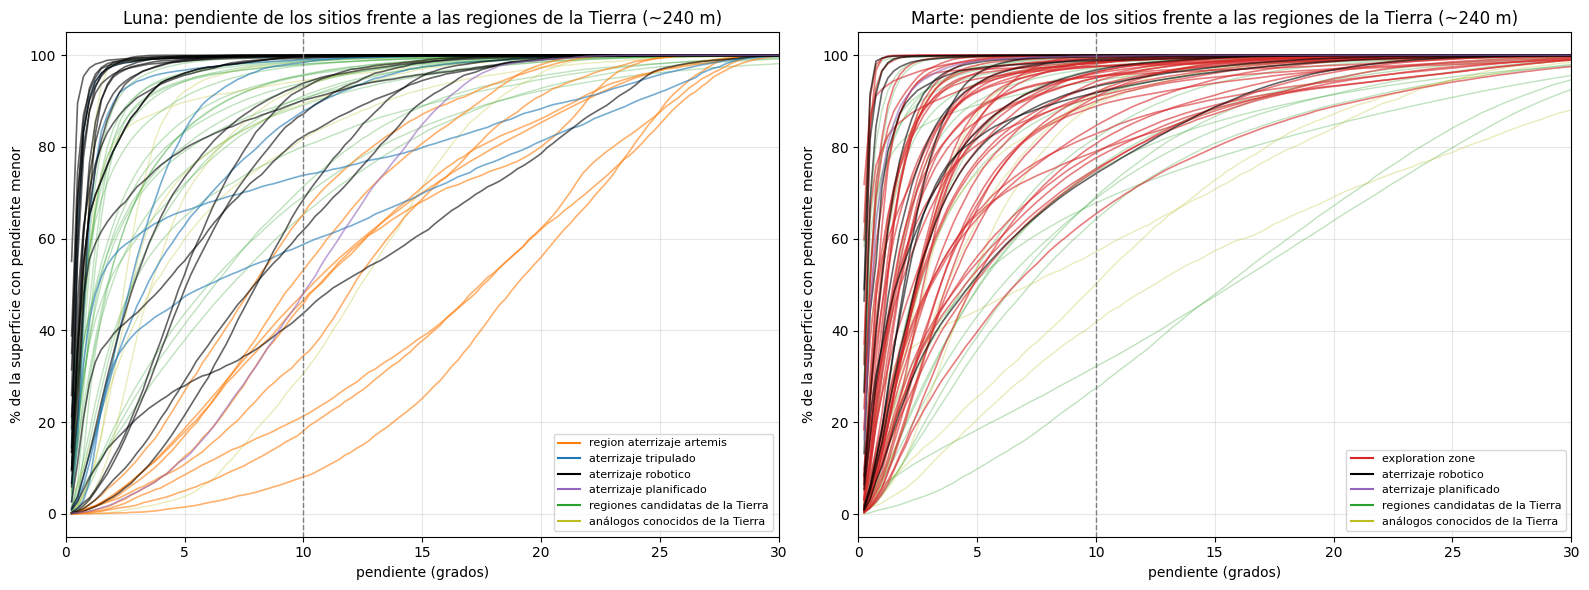

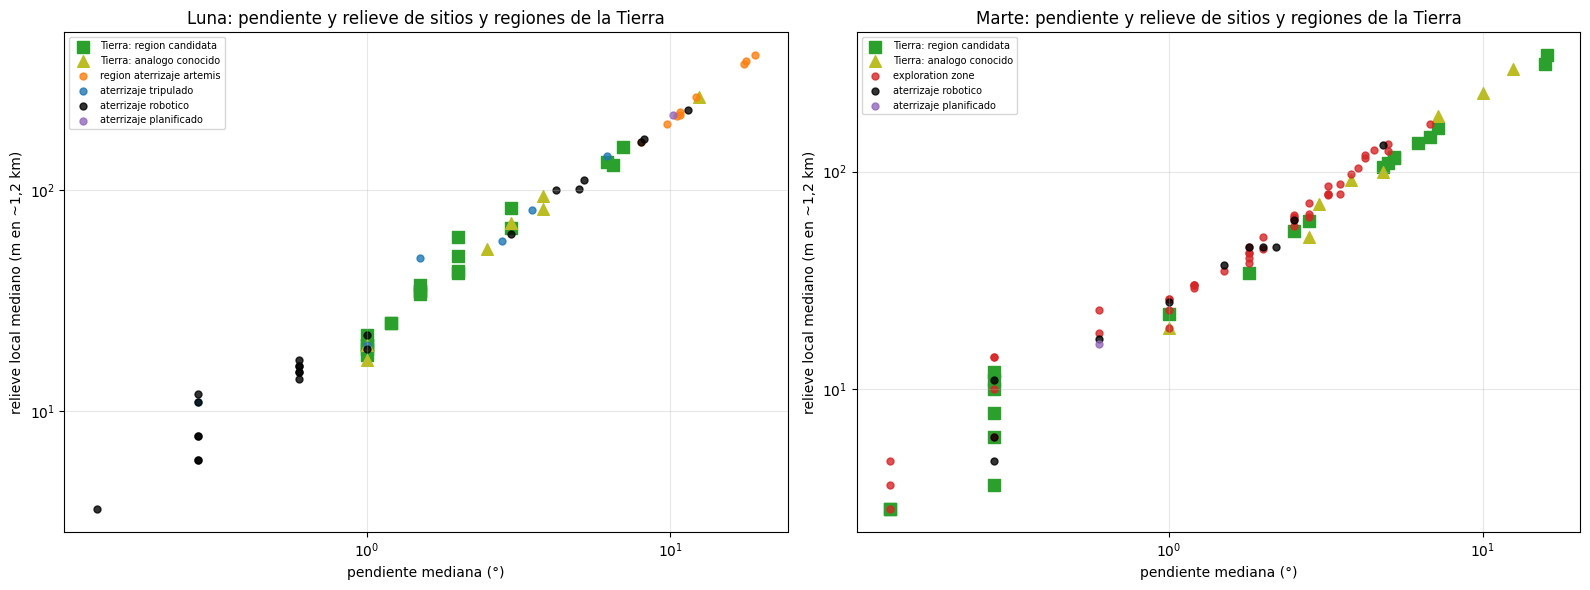

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
x = BINS[1:]
for ax, cuerpo in zip(axes, ["luna", "marte"]):
    for t in tierra[tierra.cuerpo == cuerpo].itertuples():
        ax.plot(x, cdf(H_T[t.region_id]) * 100, color="tab:green" if t.tipo_t == "region_candidata" else "tab:olive", alpha=0.3, lw=1)
    colores = {"region_aterrizaje_artemis": "tab:orange", "exploration_zone": "tab:red", "aterrizaje_tripulado": "tab:blue",
               "aterrizaje_robotico": "black", "aterrizaje_planificado": "tab:purple"}
    for tipo, color in colores.items():
        sel = sit[(sit.cuerpo == cuerpo) & (sit.tipo == tipo)]
        for r in sel.itertuples():
            if HIST[r.id].sum():
                ax.plot(x, cdf(HIST[r.id]) * 100, color=color, alpha=0.6, lw=1.2)
        if len(sel):
            ax.plot([], [], color=color, label=tipo.replace("_", " "))
    ax.plot([], [], color="tab:green", label="regiones candidatas de la Tierra")
    ax.plot([], [], color="tab:olive", label="análogos conocidos de la Tierra")
    ax.axvline(10, color="grey", ls="--", lw=1); ax.set_xlim(0, 30); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    ax.set_xlabel("pendiente (grados)"); ax.set_ylabel("% de la superficie con pendiente menor")
    ax.set_title(f"{cuerpo.capitalize()}: pendiente de los sitios frente a las regiones de la Tierra (~240 m)")
plt.tight_layout(); plt.show()

# Mapa pendiente–relieve: sitios frente a la Tierra
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, cuerpo in zip(axes, ["luna", "marte"]):
    t = tierra[tierra.cuerpo == cuerpo]
    for tipo_t, mk, c in (("region_candidata", "s", "tab:green"), ("analogo_conocido", "^", "tab:olive")):
        u = t[t.tipo_t == tipo_t]; ax.scatter(u.mediana, u.relieve_mediana, marker=mk, c=c, s=70, label=f"Tierra: {tipo_t.replace('_', ' ')}")
    for tipo, color in colores.items():
        u = sit[(sit.cuerpo == cuerpo) & (sit.tipo == tipo)]
        if len(u): ax.scatter(u.mediana, u.relieve_mediana, c=color, s=25, alpha=0.8, label=tipo.replace("_", " "))
    ax.set_xscale("symlog", linthresh=1); ax.set_yscale("symlog", linthresh=10)
    ax.set_xlabel("pendiente mediana (°)"); ax.set_ylabel("relieve local mediano (m en ~1,2 km)"); ax.grid(alpha=0.3); ax.legend(fontsize=7)
    ax.set_title(f"{cuerpo.capitalize()}: pendiente y relieve de sitios y regiones de la Tierra")
plt.tight_layout(); plt.show()

## 7. Capa para la web y registro

In [13]:
def limpio(v):
    if isinstance(v, (float, np.floating)): return None if np.isnan(v) else float(v)
    if isinstance(v, np.integer): return int(v)
    return v

salida = {"version": VERSION, "unidades": {"pendiente": "grados", "relieve": "m (máximo − mínimo en ~1,2 km)",
                                            "distancia": "media de KS de pendiente y KS de relieve, 0–1, menor es más parecido"},
          "umbral_parecido": UMBRAL_PARECIDO,
          "sitios": {r["id"]: {**{k: limpio(v) for k, v in r.items() if k != "id"},
                               "top5_tierra": [{k: limpio(v) for k, v in p.items() if k != "sitio_id"}
                                               for p in top[top.sitio_id == r["id"]].to_dict("records")]}
                     for r in sit.to_dict("records")},
          "nota": "unir con 06_web/sitios_v0/sitios.geojson por id y con topografia_v1/topografia.json por region_id"}
json.dump(salida, open(f"{WEB}/topografia_sitios.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2, allow_nan=False)
entrada = json.load(open(f"{BASE}/06_web/manifest.json", encoding="utf-8"))
entrada.setdefault("capas", {})["topografia_sitios"] = {"version": VERSION, "carpeta": VERSION, "archivo": f"{VERSION}/topografia_sitios.json"}
json.dump(entrada, open(f"{BASE}/06_web/manifest.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
registro = {"version": VERSION, "fecha": datetime.datetime.now().isoformat(timespec="seconds"),
            "datos": {"luna_polar": f"NASA LRO LOLA {PRODUCTO_POLAR} (PDS): {URL_P}", "luna": f"NASA LRO LOLA LDEM_128 (PDS): {URL_C}",
                      "marte": f"USGS HRSC–MOLA Blended DEM Global 200 m v2 (Fergason, Hare y Laura, 2018): {URL_MARTE}",
                      "tierra": "histogramas a ~240 m de topografia_v2 (Copernicus DEM GLO-30), regiones completas y análogos conocidos"},
            "orientacion_polar": {"elegida": list(ORIENT), "correlacion": round(float(pruebas[ORIENT]), 3)},
            "parametros": {"radio_luna_km": RADIO_LUNA_KM, "radio_marte_km": RADIO_MARTE_KM, "umbral_parecido": UMBRAL_PARECIDO,
                           "lado_relieve_m": LADO_RELIEVE_M, "paso_relieve_m": PASO_REL, "distancia": "media(KS pendiente, KS relieve)"},
            "conteo": {"sitios": int(len(sit)), "regiones_tierra": int(len(tierra))},
            "limitaciones": ["solo forma del terreno (pendiente y relieve): no incluye clima, materiales ni iluminación",
                             "la ventana del relieve es de 5 píxeles (~1,2 km) en Luna y Tierra y de 7 píxeles (~1,4 km) en Marte",
                             "Marte a 200 m y Tierra/Luna a ~240 m: escalas parecidas pero no idénticas",
                             "las Exploration Zones se miden en un radio de 25 km alrededor de su centro, no en sus 100 km"]}
json.dump(registro, open(f"{RES}/registro_{VERSION}.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
print("topografia_sitios.json:", f"{os.path.getsize(f'{WEB}/topografia_sitios.json') / 1e3:.0f} KB", "| capas:", list(entrada["capas"]))

topografia_sitios.json: 460 KB | capas: ['cuevas', 'topografia', 'sitios', 'topografia_sitios', 'clima', 'geologia', 'hielo', 'cuevas_sitios', 'cuevas_v2']


## 8. Conclusiones
*Rellenar al terminar.*